In [1]:
import time, random, numpy as np, torch
import torch.nn as nn, torch.optim as optim
from torch.utils.data import DataLoader, Dataset
from sklearn.metrics import accuracy_score, f1_score
import matplotlib.pyplot as plt

# Reproductibilité
SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

# GPU
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)
if device.type == "cuda":
    print(torch.cuda.get_device_name(0))

Device: cuda
Tesla T4


In [2]:
import os
for root, _, files in os.walk("/kaggle/input"):
    for f in files: print(os.path.join(root, f))

/kaggle/input/datasets/hojjatk/mnist-dataset/t10k-images.idx3-ubyte
/kaggle/input/datasets/hojjatk/mnist-dataset/t10k-labels.idx1-ubyte
/kaggle/input/datasets/hojjatk/mnist-dataset/train-images.idx3-ubyte
/kaggle/input/datasets/hojjatk/mnist-dataset/train-labels.idx1-ubyte
/kaggle/input/datasets/hojjatk/mnist-dataset/t10k-images-idx3-ubyte/t10k-images-idx3-ubyte
/kaggle/input/datasets/hojjatk/mnist-dataset/t10k-labels-idx1-ubyte/t10k-labels-idx1-ubyte
/kaggle/input/datasets/hojjatk/mnist-dataset/train-images-idx3-ubyte/train-images-idx3-ubyte
/kaggle/input/datasets/hojjatk/mnist-dataset/train-labels-idx1-ubyte/train-labels-idx1-ubyte


In [3]:
import struct

PATH = "/kaggle/input/datasets/hojjatk/mnist-dataset"   # à adapter

def read_idx_images(path):
    with open(path, "rb") as f:
        magic, n, rows, cols = struct.unpack(">IIII", f.read(16))
        return np.frombuffer(f.read(), dtype=np.uint8).reshape(n, rows, cols)

def read_idx_labels(path):
    with open(path, "rb") as f:
        magic, n = struct.unpack(">II", f.read(8))
        return np.frombuffer(f.read(), dtype=np.uint8)

X_train = read_idx_images(f"{PATH}/train-images-idx3-ubyte/train-images-idx3-ubyte")
y_train = read_idx_labels(f"{PATH}/train-labels-idx1-ubyte/train-labels-idx1-ubyte")
X_test  = read_idx_images(f"{PATH}/t10k-images-idx3-ubyte/t10k-images-idx3-ubyte")
y_test  = read_idx_labels(f"{PATH}/t10k-labels-idx1-ubyte/t10k-labels-idx1-ubyte")
print(X_train.shape, y_train.shape, X_test.shape, y_test.shape)
# attendu : (60000, 28, 28) (60000,) (10000, 28, 28) (10000,)

(60000, 28, 28) (60000,) (10000, 28, 28) (10000,)


In [4]:
import json, math
import torch.nn.functional as F
from sklearn.metrics import ConfusionMatrixDisplay

perm = torch.randperm(60000, generator=torch.Generator().manual_seed(SEED)).tolist()
train_idx, val_idx = perm[:54000], perm[54000:]

def to_t(X): return ((torch.from_numpy(X.copy()).float().div(255) - 0.1307) / 0.3081).unsqueeze(1)
def to_y(y): return torch.from_numpy(y.astype(np.int64))

Xtr, ytr = to_t(X_train[train_idx]).to(device), to_y(y_train[train_idx]).to(device)
Xva, yva = to_t(X_train[val_idx]).to(device),   to_y(y_train[val_idx]).to(device)
Xte, yte = to_t(X_test).to(device),             to_y(y_test).to(device)
print(Xtr.shape, Xva.shape, Xte.shape)

torch.Size([54000, 1, 28, 28]) torch.Size([6000, 1, 28, 28]) torch.Size([10000, 1, 28, 28])


In [5]:
def patchify(images, p):
    """(B,1,28,28) -> (B, N, p*p) : suite de patchs aplatis."""
    B, C, H, W = images.shape
    x = images.unfold(2, p, p).unfold(3, p, p)               # B,C,H/p,W/p,p,p
    return x.permute(0, 2, 3, 1, 4, 5).reshape(B, (H // p) * (W // p), C * p * p)

def positional_embeddings(n_tokens, dim):
    pos = torch.arange(n_tokens).unsqueeze(1)
    div = torch.exp(torch.arange(0, dim, 2) * (-math.log(10000.0) / dim))
    pe = torch.zeros(n_tokens, dim)
    pe[:, 0::2], pe[:, 1::2] = torch.sin(pos * div), torch.cos(pos * div)
    return pe

class MSA(nn.Module):                                         # attention multi-têtes
    def __init__(self, dim, heads, dropout):
        super().__init__()
        self.h, self.dk = heads, dim // heads
        self.qkv  = nn.Linear(dim, 3 * dim)
        self.proj = nn.Linear(dim, dim)
        self.drop = nn.Dropout(dropout)
    def forward(self, x):
        B, N, D = x.shape
        q, k, v = self.qkv(x).reshape(B, N, 3, self.h, self.dk).permute(2, 0, 3, 1, 4)
        att = self.drop(((q @ k.transpose(-2, -1)) / math.sqrt(self.dk)).softmax(-1))
        return self.proj((att @ v).transpose(1, 2).reshape(B, N, D))

class Block(nn.Module):                                       # bloc encodeur
    def __init__(self, dim, heads, mlp_dim, dropout):
        super().__init__()
        self.n1, self.n2 = nn.LayerNorm(dim), nn.LayerNorm(dim)
        self.msa = MSA(dim, heads, dropout)
        self.mlp = nn.Sequential(nn.Linear(dim, mlp_dim), nn.GELU(), nn.Dropout(dropout),
                                 nn.Linear(mlp_dim, dim), nn.Dropout(dropout))
    def forward(self, x):
        x = x + self.msa(self.n1(x))
        return x + self.mlp(self.n2(x))

class ViT(nn.Module):
    def __init__(self, patch=4, dim=64, depth=4, heads=4, mlp_dim=128, n_classes=10, dropout=0.1):
        super().__init__()
        self.p = patch
        n_patches = (28 // patch) ** 2
        self.embed = nn.Linear(patch * patch, dim)            # projection linéaire des patchs
        self.cls = nn.Parameter(torch.randn(1, 1, dim) * 0.02) # token de classe
        self.register_buffer("pos", positional_embeddings(n_patches + 1, dim))
        self.blocks = nn.Sequential(*[Block(dim, heads, mlp_dim, dropout) for _ in range(depth)])
        self.norm = nn.LayerNorm(dim)
        self.head = nn.Linear(dim, n_classes)
    def forward(self, x):
        t = self.embed(patchify(x, self.p))
        t = torch.cat([self.cls.expand(len(t), -1, -1), t], dim=1) + self.pos
        t = self.blocks(t)
        return self.head(self.norm(t[:, 0]))                  # classification depuis le token de classe

model = ViT().to(device)
print("Paramètres :", sum(p.numel() for p in model.parameters()))
print(model(Xtr[:4]).shape)    # attendu : torch.Size([4, 10])

Paramètres : 135818
torch.Size([4, 10])


In [6]:
@torch.no_grad()
def evaluate(model, X, y, bs=512):
    model.eval(); tot, preds = 0.0, []
    for i in range(0, len(y), bs):
        out = model(X[i:i+bs])
        tot += F.cross_entropy(out, y[i:i+bs], reduction="sum").item()
        preds.append(out.argmax(1))
    preds, labels = torch.cat(preds).cpu().numpy(), y.cpu().numpy()
    return (tot / len(labels), accuracy_score(labels, preds),
            f1_score(labels, preds, average="macro"), preds, labels)

def fit(model, epochs=10, lr=1e-3, wd=0.05, bs=128, warm=200):
    opt = optim.AdamW(model.parameters(), lr=lr, weight_decay=wd)
    steps = epochs * math.ceil(len(ytr) / bs)
    sched = optim.lr_scheduler.LambdaLR(
        opt, lambda s: min(1.0, (s + 1) / warm) * 0.5 * (1 + math.cos(math.pi * min(1.0, s / steps))))
    hist = {"train_loss": [], "val_loss": [], "val_acc": []}
    torch.cuda.synchronize(); t0 = time.time()
    for ep in range(epochs):
        model.train(); running = 0.0
        order = torch.randperm(len(ytr), device=device)
        for i in range(0, len(order), bs):
            idx = order[i:i+bs]
            loss = F.cross_entropy(model(Xtr[idx]), ytr[idx])
            opt.zero_grad(); loss.backward(); opt.step(); sched.step()
            running += loss.item() * len(idx)
        v_loss, v_acc, v_f1, _, _ = evaluate(model, Xva, yva)
        hist["train_loss"].append(running / len(ytr))
        hist["val_loss"].append(v_loss); hist["val_acc"].append(v_acc)
        print(f"Epoch {ep+1:2d}/{epochs} | train loss {hist['train_loss'][-1]:.4f} | "
              f"val loss {v_loss:.4f} | val acc {v_acc:.4f} | val F1 {v_f1:.4f} | {time.time()-t0:.0f} s")
    torch.cuda.synchronize()
    return hist, time.time() - t0

history, train_time = fit(model, epochs=10)
print(f"Temps d'entraînement : {train_time:.1f} s")

Epoch  1/10 | train loss 1.0528 | val loss 0.2392 | val acc 0.9280 | val F1 0.9270 | 5 s
Epoch  2/10 | train loss 0.2382 | val loss 0.1497 | val acc 0.9542 | val F1 0.9537 | 9 s
Epoch  3/10 | train loss 0.1625 | val loss 0.1197 | val acc 0.9637 | val F1 0.9633 | 13 s
Epoch  4/10 | train loss 0.1250 | val loss 0.1036 | val acc 0.9665 | val F1 0.9662 | 17 s
Epoch  5/10 | train loss 0.1017 | val loss 0.0859 | val acc 0.9723 | val F1 0.9721 | 21 s
Epoch  6/10 | train loss 0.0833 | val loss 0.0813 | val acc 0.9752 | val F1 0.9751 | 25 s
Epoch  7/10 | train loss 0.0691 | val loss 0.0744 | val acc 0.9773 | val F1 0.9771 | 29 s
Epoch  8/10 | train loss 0.0594 | val loss 0.0709 | val acc 0.9792 | val F1 0.9789 | 33 s
Epoch  9/10 | train loss 0.0509 | val loss 0.0671 | val acc 0.9807 | val F1 0.9805 | 37 s
Epoch 10/10 | train loss 0.0467 | val loss 0.0667 | val acc 0.9808 | val F1 0.9807 | 42 s
Temps d'entraînement : 41.6 s


TEST | loss 0.0567 | acc 0.9823 | F1 0.9822


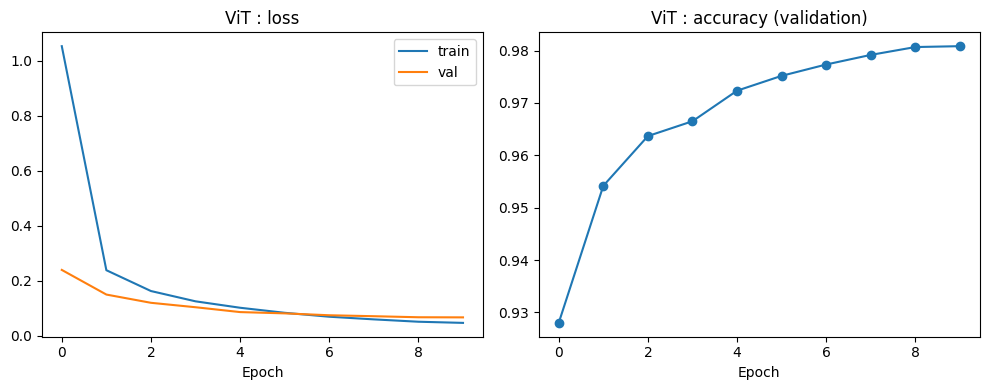

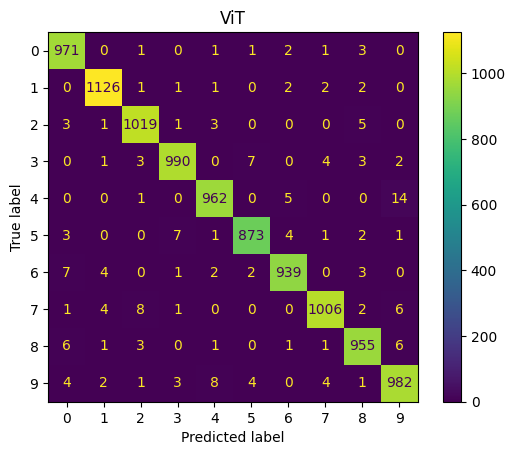

{'ViT': {'accuracy': 0.9823, 'f1': 0.9821731743497827, 'loss': 0.056739840221405026, 'time_s': 41.565752267837524, 'params': 135818}}


In [7]:
t_loss, t_acc, t_f1, preds, labels = evaluate(model, Xte, yte)
print(f"TEST | loss {t_loss:.4f} | acc {t_acc:.4f} | F1 {t_f1:.4f}")

n_params = sum(p.numel() for p in model.parameters())
results = {"ViT": {"accuracy": t_acc, "f1": t_f1, "loss": t_loss,
                   "time_s": train_time, "params": n_params}}

plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
plt.plot(history["train_loss"], label="train"); plt.plot(history["val_loss"], label="val")
plt.title("ViT : loss"); plt.xlabel("Epoch"); plt.legend()
plt.subplot(1, 2, 2); plt.plot(history["val_acc"], marker="o")
plt.title("ViT : accuracy (validation)"); plt.xlabel("Epoch")
plt.tight_layout(); plt.savefig("vit_curves.png", dpi=150); plt.show()

ConfusionMatrixDisplay.from_predictions(labels, preds)
plt.title("ViT"); plt.savefig("vit_confusion.png", dpi=150); plt.show()

json.dump(results, open("results_vit.json", "w"), indent=2)
torch.save(model.state_dict(), "vit_mnist.pth")
print(results)

               accuracy      f1    loss    time_s       params
CNN (scratch)    0.9904  0.9903  0.0289   22.6000     421834.0
Faster R-CNN     0.9818  0.9817  0.1250  395.4000   28329606.0
AlexNet (FT)     0.9819  0.9819  0.0646   24.4000   57044810.0
VGG16 (FT)       0.9896  0.9896  0.0425   77.7000  134301514.0
ViT (scratch)    0.9823  0.9822  0.0567   41.5658     135818.0


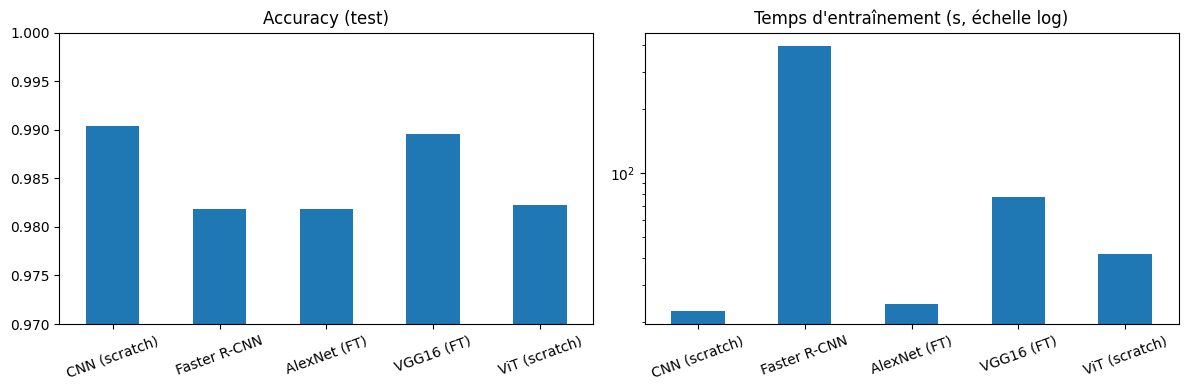

In [8]:
import pandas as pd
rows = {
 "CNN (scratch)": {"accuracy": 0.9904, "f1": 0.9903, "loss": 0.0289, "time_s": 22.6,  "params": 421_834},
 "Faster R-CNN":  {"accuracy": 0.9818, "f1": 0.9817, "loss": 0.1250, "time_s": 395.4, "params": 28_329_606},
 "AlexNet (FT)":  {"accuracy": 0.9819, "f1": 0.9819, "loss": 0.0646, "time_s": 24.4,  "params": 57_044_810},
 "VGG16 (FT)":    {"accuracy": 0.9896, "f1": 0.9896, "loss": 0.0425, "time_s": 77.7,  "params": 134_301_514},
 "ViT (scratch)": results["ViT"],
}
df = pd.DataFrame(rows).T[["accuracy", "f1", "loss", "time_s", "params"]]
print(df.round(4).to_string())
df.to_csv("comparison_final.csv")

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
df["accuracy"].plot.bar(ax=ax[0], ylim=(0.97, 1.0), title="Accuracy (test)", rot=20)
df["time_s"].plot.bar(ax=ax[1], logy=True, title="Temps d'entraînement (s, échelle log)", rot=20)
plt.tight_layout(); plt.savefig("comparison_final.png", dpi=150); plt.show()